# Comparing Turbines and Their LiDAR Measurments
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Loading in Datasets

In [2]:
# load in turbine and lidar datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
lidar_159 = pd.read_parquet('../../data/cleaned/WTG159_lidar.parquet')
lidar_170 = pd.read_parquet('../../data/cleaned/WTG170_lidar.parquet')
lidar_171 = pd.read_parquet('../../data/cleaned/WTG171_lidar.parquet')
lidar_173 = pd.read_parquet('../../data/cleaned/WTG173_lidar.parquet')
lidar_180 = pd.read_parquet('../../data/cleaned/WTG180_lidar.parquet')
lidar_184 = pd.read_parquet('../../data/cleaned/WTG184_lidar.parquet')

In [3]:
scada['utc'] = scada['utc'] + pd.to_timedelta(8, unit = 'h')

## Combining LiDAR Datasets with SCADA Information
### Functions Defined

In [4]:
def missing_intervals(df_full, turbine, var):
    # defining dataset
    df = df_full[df_full['turbine'] == turbine]
    
    # define stepcount for dataset and sort by datetime
    step = pd.Timedelta(minutes = 10)
    df = df.sort_values('utc').reset_index(drop = True)

    # define missing values
    is_missing = df[var].isna()
    run_id = (is_missing != is_missing.shift()).cumsum()

    # summarize values from before the outages
    roll = df.set_index('utc')[var].rolling('30min', closed = 'left')
    df['prev_30_avg'] = roll.mean().to_numpy()
    df['prev_30_n'] = roll.count().to_numpy()
    df['prev_value'] = df[var].shift(1)
    df['next_value'] = df[var].shift(-1)
    
    # summarizing each interval
    summary = (df[is_missing].groupby(run_id[is_missing]).agg(start = ('utc', 'first'), obs_count = ('utc', 'size'), 
                                                              prev_value = ('prev_value', 'first'), next_value = ('next_value', 'last'), 
                                                              prev_30_avg = ('prev_30_avg', 'first'), 
                                                              prev_30_n = ('prev_30_n', 'first')).reset_index(drop = True))
    summary['length'] = summary['obs_count'] * step
    summary['end'] = summary['start'] + summary['length']

    return summary

In [5]:
def merge_lidar(full, lidar, selected, a, b):
    result = pd.merge(full, lidar, on = ['utc', 'turbine'], how = 'inner')[selected]

    result['diff'] = result[b] - result[a]
    result['perc_dev'] = np.where(result[a] != 0, ((result[b] - result[a]) / result[a]) * 100, np.nan)
    result['perc_diff'] = (np.abs(result[b] - result[a]) / ((result[a] + result[b]) / 2)) * 100

    return result

In [6]:
columns = ['utc', 'turbine', 'wind_speed', 'KPI_wind_speed', 'wind_direction', 'wind_direction_relative', 
           'wind_speed_l', 'wind_speed_l_std', 'wind_speed_l1', 'wind_speed_l1_std', 'wind_direction_l', 'air_density']

ref, var = 'wind_speed_l', 'wind_speed'

### WTG159

In [7]:
WTG159 = merge_lidar(full = scada, lidar = lidar_159, selected = columns, a = ref, b = var)

In [8]:
WTG159['utc'].describe()

count                            14921
mean     2026-06-08 12:07:53.413309952
min                2026-04-16 01:10:00
25%                2026-05-13 04:00:00
50%                2026-06-08 01:40:00
75%                2026-07-03 23:20:00
max                2026-08-05 07:50:00
Name: utc, dtype: object

In [9]:
WTG159['perc_dev'].describe()

count    14666.000000
mean        19.196276
std         53.333540
min        -91.007154
25%          8.061991
50%         12.350106
75%         17.732095
max        996.703800
Name: perc_dev, dtype: float64

In [10]:
WTG159.sort_values('diff', ascending = False).head()

,utc,turbine,wind_speed,KPI_wind_speed,wind_direction,wind_direction_relative,wind_speed_l,wind_speed_l_std,wind_speed_l1,wind_speed_l1_std,wind_direction_l,air_density,diff,perc_dev,perc_diff
4335,2026-05-17 08:50:00,WTG159,36.241115,36.257748,159.740458,-9.259542,3.66,0.73,31.06,2.25,0.38,1.066365,32.581115,890.194411,163.309296
4334,2026-05-17 08:40:00,WTG159,36.128464,36.137770,154.847222,-14.152778,4.26,0.88,30.81,2.20,-0.21,1.066065,31.868464,748.085998,157.809734
4330,2026-05-17 08:00:00,WTG159,34.875181,34.997955,158.242857,-10.757143,3.18,0.53,29.82,3.08,1.82,1.065252,31.695181,996.703800,166.574853
4333,2026-05-17 08:30:00,WTG159,36.254120,36.282680,156.239130,-12.760870,4.83,0.73,31.05,2.51,0.16,1.065734,31.424120,650.602889,152.974531
4331,2026-05-17 08:10:00,WTG159,34.463661,34.479565,156.972028,-12.027972,3.20,0.58,29.46,2.47,0.54,1.065239,31.263661,976.989397,166.014987


In [11]:
# analyzing which columns have the most missing data
na_pct_159 = WTG159.isna().mean()

print(na_pct_159.sort_values(ascending = False))

wind_speed_l_std           0.017425
perc_diff                  0.017090
perc_dev                   0.017090
diff                       0.017090
wind_speed_l               0.016085
wind_direction_l           0.016085
KPI_wind_speed             0.012734
air_density                0.003686
wind_speed                 0.001273
wind_direction_relative    0.001072
wind_direction             0.001072
wind_speed_l1_std          0.000134
wind_speed_l1              0.000134
utc                        0.000000
turbine                    0.000000
dtype: float64


(0.0, 38.0)

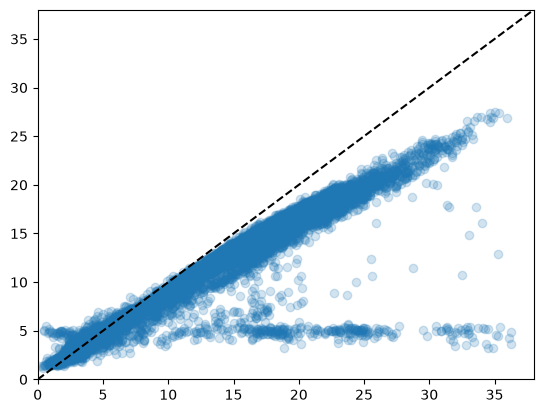

In [12]:
plt.scatter(x = WTG159['wind_speed'], y = WTG159['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)

### WTG170

In [11]:
WTG170 = merge_lidar(full = scada, lidar = lidar_170, selected = columns, a = ref, b = var)

In [14]:
WTG170['perc_dev'].describe()

count    16761.000000
mean         7.123887
std         19.906456
min        -95.619581
25%          1.546200
50%          5.579153
75%         10.055891
max        782.851089
Name: perc_dev, dtype: float64

In [46]:
WTG170['period'] = WTG170['utc'].dt.to_period('W')

jan = WTG170[WTG170['period'] == '2026-04-01']

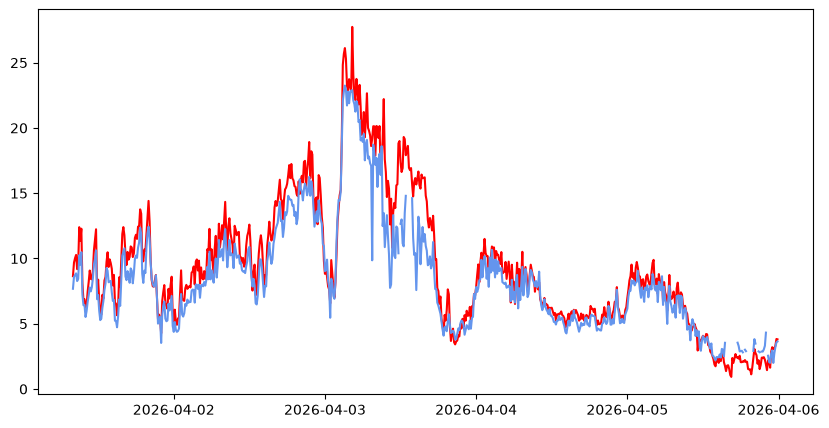

In [47]:
plt.figure(figsize = (10, 5))

plt.plot(jan['utc'], jan['wind_speed'], color = 'red')
plt.plot(jan['utc'], jan['wind_speed_l'], color = 'cornflowerblue')
plt.show()

(0.0, 38.0)

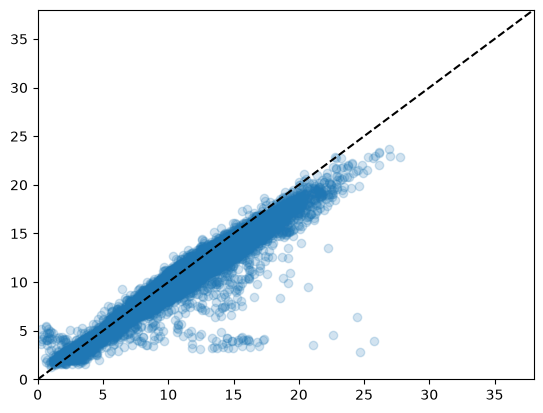

In [39]:
plt.scatter(x = WTG170['wind_speed'], y = WTG170['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)

### WTG171

In [19]:
WTG171 = merge_lidar(full = scada, lidar = lidar_171, selected = columns, a = ref, b = var)

In [21]:
WTG171['perc_dev'].describe()

count    13586.000000
mean         0.910525
std         16.181739
min        -93.214690
25%         -5.545941
50%          2.807155
75%          7.715799
max        424.650448
Name: perc_dev, dtype: float64

(0.0, 38.0)

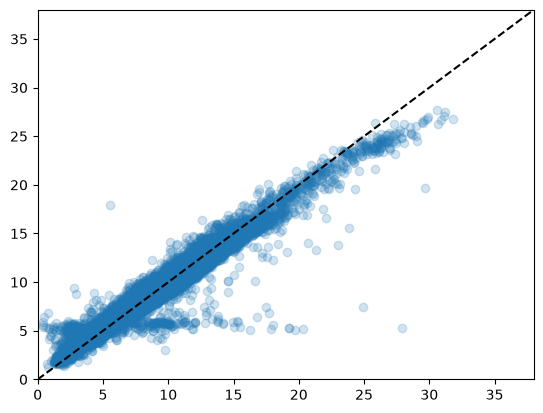

In [40]:
plt.scatter(x = WTG171['wind_speed'], y = WTG171['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)

### WTG173

In [23]:
WTG173 = merge_lidar(full = scada, lidar = lidar_173, selected = columns, a = ref, b = var)

In [24]:
WTG173['perc_dev'].describe()

count    16756.000000
mean         3.688554
std         29.755540
min        -91.538296
25%         -5.166024
50%          0.797939
75%          6.117591
max        646.430764
Name: perc_dev, dtype: float64

(0.0, 38.0)

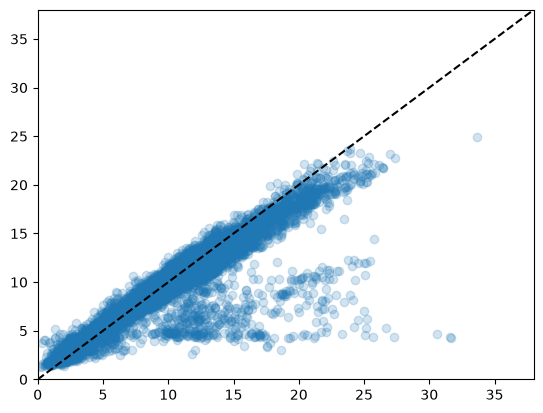

In [41]:
plt.scatter(x = WTG173['wind_speed'], y = WTG173['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)

### WTG180

In [26]:
WTG180 = merge_lidar(full = scada, lidar = lidar_180, selected = columns, a = ref, b = var)

In [50]:
WTG180

,utc,turbine,wind_speed,KPI_wind_speed,wind_direction,wind_direction_relative,wind_speed_l,wind_speed_l_std,wind_speed_l1,wind_speed_l1_std,wind_direction_l,air_density,diff,perc_dev,perc_diff
0,2026-04-01 08:00:00,WTG180,11.230475,11.201847,302.926380,-4.582090,10.95,1.23,12.36,1.44,1.13,1.065109,0.280475,2.561417,2.529027
1,2026-04-01 08:10:00,WTG180,10.281649,10.305550,302.965517,-3.312057,9.90,1.46,11.48,1.75,1.74,0.771651,0.381649,3.855043,3.782141
2,2026-04-01 08:20:00,WTG180,9.064360,9.067080,307.936047,-4.246377,9.13,0.86,10.33,1.30,0.91,1.068284,-0.065640,-0.718952,0.721546
3,2026-04-01 08:30:00,WTG180,9.557285,9.566446,311.089041,-5.080292,9.66,0.67,10.81,1.19,0.03,1.070566,-0.102715,-1.063304,1.068987
4,2026-04-01 08:40:00,WTG180,10.374485,10.345365,313.743421,-7.742857,9.83,0.90,11.56,1.25,-1.00,1.073015,0.544485,5.539013,5.389743
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17206,2026-08-05 07:10:00,WTG180,10.292255,NaN,276.468927,-6.091549,9.74,1.07,11.47,1.40,-0.73,NaN,0.552255,5.669973,5.513662
17207,2026-08-05 07:20:00,WTG180,10.402440,NaN,283.179012,-1.791667,9.79,1.26,11.56,1.22,4.17,NaN,0.612440,6.255771,6.066032
17208,2026-08-05 07:30:00,WTG180,10.094338,NaN,278.951724,-6.048276,9.73,1.17,11.27,1.35,-0.13,NaN,0.364338,3.744480,3.675663
17209,2026-08-05 07:40:00,WTG180,10.106830,NaN,292.239130,-4.097222,9.40,1.37,11.35,1.80,1.60,NaN,0.706830,7.519464,7.246997


In [49]:
WTG180['perc_diff'].describe()

count    17152.000000
mean         6.936172
std          8.225983
min          0.000072
25%          2.225594
50%          4.675696
75%          8.661916
max        147.400407
Name: perc_diff, dtype: float64

(0.0, 38.0)

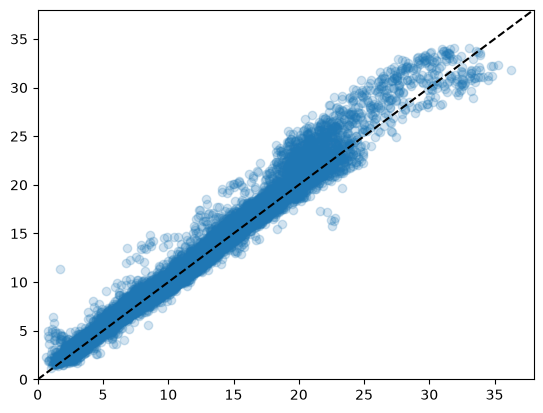

In [42]:
plt.scatter(x = WTG180['wind_speed'], y = WTG180['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)

### WTG184

In [29]:
WTG184 = merge_lidar(full = scada, lidar = lidar_184, selected = columns, a = ref, b = var)

In [30]:
WTG184['perc_dev'].describe()

count    16422.000000
mean         1.770025
std         10.851788
min        -65.447834
25%         -2.623118
50%          3.710032
75%          7.846030
max        254.545534
Name: perc_dev, dtype: float64

(0.0, 38.0)

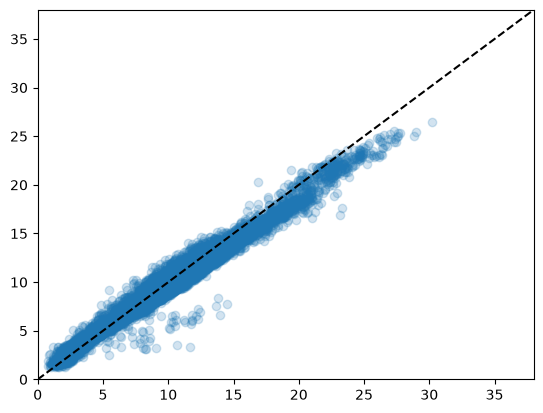

In [43]:
plt.scatter(x = WTG184['wind_speed'], y = WTG184['wind_speed_l'], alpha = 0.2)
plt.axline([0, 0], slope = 1, color = 'black', linestyle = '--')
plt.xlim(0, 38)
plt.ylim(0, 38)